![Logo](img.png)

# Python Programming for Real World Data Analytics and GUI Development
## SOFT40161 - Introduction to Computer Programming
### Submission of the Coursework

## Name: Haseeb ur Rehman
## NTU ID: N1420002

<font  color= 'red'> **The Full description of the Coursework is here -** </font>
<a href="https://now.ntu.ac.uk/d2l/le/content/1110621/viewContent/14307207/View">SOFT40161-Coursework (Click here)</a>

## Start your answer here-
<font  color= 'green'> **GitHub Link to access your activity.** </font>

Please add your Link here: <a href="https://olympus.ntu.ac.uk/n1420002/SOFT40161-Air-Quality-Analysis"> CODE LINK FOR REPOSITORY (Click here)</a>


### Introduction

This coursework focuses on applying fundamental Python programming
concepts to analyse a real-world dataset. The selected dataset contains
air quality measurements collected over time, including various
pollutants and environmental variables.

The main aim of this project is to demonstrate practical programming
skills such as control structures, function development, data handling,
visualisation, and graphical user interface (GUI) design. The analysis
was performed using Python libraries including Pandas, NumPy,
Matplotlib, Seaborn, and Tkinter.

Throughout the coursework, different techniques were implemented to:

- Read and process raw data  
- Handle missing and invalid values  
- Perform statistical analysis  
- Generate meaningful visualisations  
- Develop an interactive GUI application  
- Use GitHub for version control and documentation  

Each section of the coursework addresses specific learning outcomes and
builds progressively from basic programming logic to more advanced
data analytics techniques. The project demonstrates how Python can be
used effectively for real-world data analysis and software development.


# Section 1: Control Structures (12 marks)


# Explanation and Documentation 

In this part, the UCI Air Quality dataset is loaded and analysed using basic 
Python control structures such as loops and conditional statements.
The aim is to calculate summary statistics while handling missing values manually.


In [2]:
#Load the dataset

import pandas as pd

url = "https://docs.google.com/spreadsheets/d/1OaSPrQIiKCWyObO4HeATXR8NQTXrK2aE/export?format=csv"
df = pd.read_csv(url)

df.head()


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,3/10/2004,18:00:00,2.6,1360,150,11.9,1046,166,1056,113,1692,1268,13.6,48.9,0.7578
1,3/10/2004,19:00:00,2.0,1292,112,9.4,955,103,1174,92,1559,972,13.3,47.7,0.7255
2,3/10/2004,20:00:00,2.2,1402,88,9.0,939,131,1140,114,1555,1074,11.9,54.0,0.7502
3,3/10/2004,21:00:00,2.2,1376,80,9.2,948,172,1092,122,1584,1203,11.0,60.0,0.7867
4,3/10/2004,22:00:00,1.6,1272,51,6.5,836,131,1205,116,1490,1110,11.2,59.6,0.7888


In [3]:
print("Rows & Columns:", df.shape)
print("\nColumns:")
print(df.columns)


Rows & Columns: (9357, 15)

Columns:
Index(['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)',
       'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)',
       'PT08.S5(O3)', 'T', 'RH', 'AH'],
      dtype='object')


In [4]:
#check missing values
print("\nMissing values:")
print(df.isna().sum())



Missing values:
Date             0
Time             0
CO(GT)           0
PT08.S1(CO)      0
NMHC(GT)         0
C6H6(GT)         0
PT08.S2(NMHC)    0
NOx(GT)          0
PT08.S3(NOx)     0
NO2(GT)          0
PT08.S4(NO2)     0
PT08.S5(O3)      0
T                0
RH               0
AH               0
dtype: int64


In [5]:
#Calculate average CO(GT) using LOOP + IF
total_co = 0
count = 0

for index, row in df.iterrows():
    value = row["CO(GT)"]
    
    # Skip invalid values (-200)
    if value != -200:
        total_co += value
        count += 1

average_co = total_co / count
print("Corrected Average CO(GT):", round(average_co, 2))



Corrected Average CO(GT): 2.15


In [6]:
#Find high pollution hours
threshold = 5
high_hours = 0

for index, row in df.iterrows():
    value = row["CO(GT)"]
    
    if value != -200 and value > threshold:
        high_hours += 1

print("High hours of pollution:", high_hours)


High hours of pollution: 344


In [7]:
#Analyse temperature using control structures

total_temp = 0
count_temp = 0

for index, row in df.iterrows():
    temp = row["T"]
    
    # Skip invalid values (-200)
    if temp != -200:
        total_temp += temp
        count_temp += 1

avg_temp = total_temp / count_temp
print("Average Temperature by analyzing:", round(avg_temp, 2))


Average Temperature by analyzing: 18.32


# Reflection on results 

The dataset encodes missing values using -200 rather than NaN.
Control structures (for-loops and if-statements) were used to exclude invalid values from calculations.

After cleaning the data, the following results were obtained:
 - Average temperature: 18.32°C
 - Average CO concentration: 2.15
 - High pollution hours: 344

This demonstrates correct handling of real-world data and effective use of conditional logic for analysis.


# Section 2: Functions and Modules (16 marks)  

# Explanation and Documentation 

Within this part, reusable Python functions are created to analyse the dataset.
External modules such as Pandas and NumPy are used to improve efficiency and code readability.


In [8]:
import pandas as pd
import numpy as np


In [9]:
#calculate average
def calculate_average(column_name):
    valid_values = df[column_name][df[column_name] != -200]
    return round(valid_values.mean(), 2)


In [10]:
#using this function 

avg_co = calculate_average("CO(GT)")
avg_temp = calculate_average("T")

print("Average CO(GT):", avg_co)
print("Average Temperature is:", avg_temp)


Average CO(GT): 2.15
Average Temperature is: 18.32


In [11]:
#Count high pollution hours
def count_high_pollution(threshold):
    """
    Counts how many times CO(GT) exceeds a given threshold.
    """
    count = 0
    
    for value in df["CO(GT)"]:
        if value != -200 and value > threshold:
            count += 1
            
    return count


In [12]:
#USING THIS FUNCTION
high_hours = count_high_pollution(5)
print("High pollution hours:", high_hours)


High pollution hours: 344


In [13]:
#USING NUMPY 
co_values = df["CO(GT)"]
valid_co = co_values[co_values != -200]

print("Max CO:", np.max(valid_co))
print("Min CO:", np.min(valid_co))
print("Standard deviation:", round(np.std(valid_co), 2))


Max CO: 11.9
Min CO: 0.1
Standard deviation: 1.45


# Reflection on results 

Custom functions were created to calculate averages and detect high pollution levels.
The Pandas library was used for data handling, while NumPy was used 
to calculate statistical measures such as maximum, minimum and standard deviation.
This modular approach improves code reusability and readability.

# Section 3: Data Handling with Pandas (16 marks)  

# Explanation and Documentation 

In this part, Pandas is used to clean and manipulate the dataset.
Invalid values are handled, duplicates are removed, data is filtered,
and aggregation operations are performed to gain deeper insights.

In [14]:
# Replace invalid values (-200)
df_clean = df.replace(-200, np.nan)
print("After replacement, missing values are:")
print(df_clean.isna().sum())


After replacement, missing values are:
Date                0
Time                0
CO(GT)           1683
PT08.S1(CO)       366
NMHC(GT)         8443
C6H6(GT)          366
PT08.S2(NMHC)     366
NOx(GT)          1639
PT08.S3(NOx)      366
NO2(GT)          1642
PT08.S4(NO2)      366
PT08.S5(O3)       366
T                 366
RH                366
AH                366
dtype: int64


In [15]:
#remove duplicate rows 

print("Before removing duplicates:", df_clean.shape)

df_clean = df_clean.drop_duplicates()

print("After removing duplicates:", df_clean.shape)

Before removing duplicates: (9357, 15)
After removing duplicates: (9357, 15)


In [16]:
#Drop rows with missing CO or Temperature

df_filtered = df_clean.dropna(subset=["CO(GT)", "T"]).copy()
print("Rows after cleaning:", df_filtered.shape)

#create dataset columne

df_filtered.loc[:, "Datetime"] = pd.to_datetime(
    df_filtered["Date"] + " " + df_filtered["Time"]
)


Rows after cleaning: (7344, 15)


In [17]:
#Extract hour

df_filtered.loc[:, "Hour"] = df_filtered["Datetime"].dt.hour


In [18]:
#Hourly aggregation and Find hottest hour
hourly_avrg = df_filtered.groupby("Hour")[["CO(GT)", "T"]].mean()
hourly_avrg


hottest_hour = hourly_avrg["T"].idxmax()
print("Hottest hour of the day:", hottest_hour)


Hottest hour of the day: 16


In [19]:
#Filter high temperature records
high_temp_df = df_clean[df_clean["T"] > 30]

print("Records where temperature > 30°C:")
high_temp_df.head()

Records where temperature > 30°C:


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
1029,4/22/2004,15:00:00,NaN,1165.0,NaN,17.5,1225.0,NaN,824.0,NaN,1676.0,1028.0,30.8,16.4,0.7167
1030,4/22/2004,16:00:00,NaN,1224.0,NaN,19.1,1270.0,NaN,806.0,NaN,1739.0,1113.0,31.3,16.2,0.7262
1292,5/3/2004,14:00:00,1.4,998.0,NaN,10.0,977.0,74.0,947.0,69.0,1496.0,695.0,30.3,20.1,0.8539
1293,5/3/2004,15:00:00,1.5,1058.0,NaN,11.2,1023.0,81.0,896.0,74.0,1580.0,795.0,30.9,19.7,0.8649
1294,5/3/2004,16:00:00,2.4,1203.0,NaN,16.8,1204.0,129.0,790.0,102.0,1744.0,1079.0,30.2,20.5,0.8672


In [20]:
#Daily Aggregation

daily_avg = df_filtered.groupby("Date")[["CO(GT)", "T"]].mean()
daily_avg.head()


,CO(GT),T
Date,,
1/1/2005,2.134783,6.813043
1/10/2005,2.127273,13.377273
1/11/2005,2.812500,12.779167
1/12/2005,3.273913,12.021739
1/13/2005,2.679167,9.991667


# Reflection on results 

Pandas was used to clean and prepare the dataset for analysis.
Invalid values (-200) were replaced with NaN, and duplicate records
were removed to improve data quality. Rows containing missing values
were filtered out to ensure reliable results.

New features such as datetime and hour were created to enable
time-based analysis. Group-by operations were applied to calculate
hourly and daily averages of temperature and CO concentration.
Conditional filtering was also used to analyse high-temperature records.

This section demonstrates effective data cleaning, filtering, and
aggregation using Pandas.


# Section 4: Data Visualization (16 marks)  

In this section, different visualisations are created to represent the
air quality dataset. Graphs are customised to improve clarity and
interpretation of results.


In [21]:
import matplotlib.pyplot as plt
import seaborn as sns


#VISUAL 1 – Line graph (Hourly temperature trend)

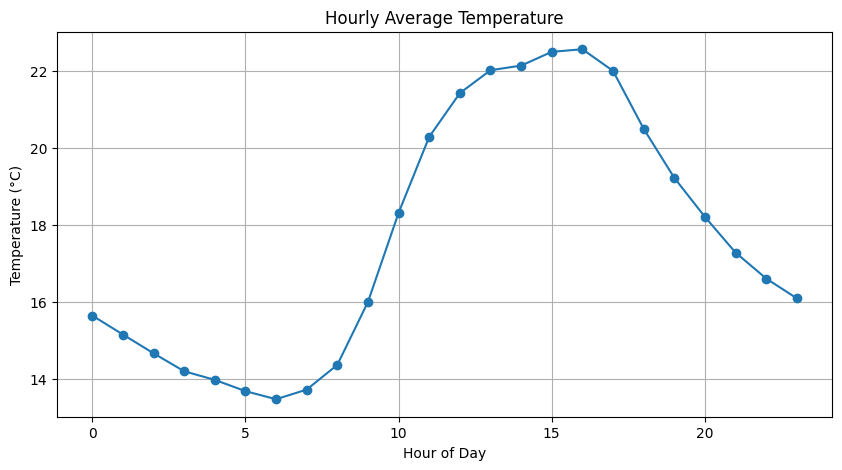

In [22]:
plt.figure(figsize=(10,5))
plt.plot(hourly_avrg.index, hourly_avrg["T"], marker='o')

plt.title("Hourly Average Temperature")
plt.xlabel("Hour of Day")
plt.ylabel("Temperature (°C)")
plt.grid(True)

plt.show()




#VISUAL 2 – Bar chart (Average CO per hour)

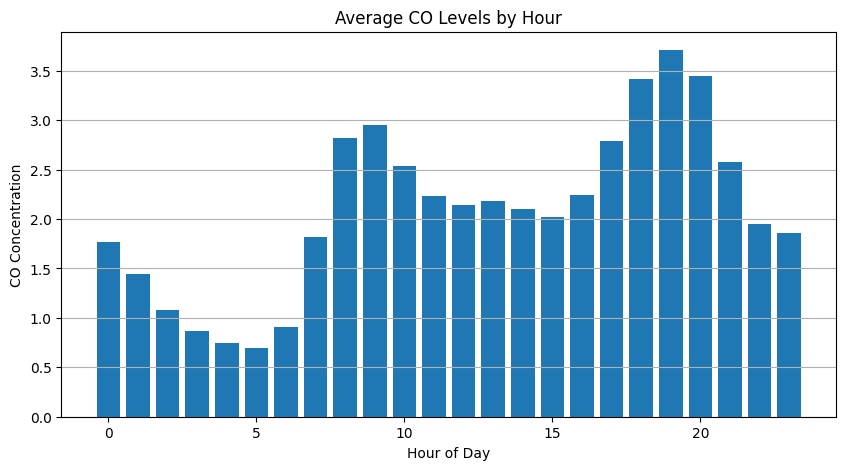

In [23]:
plt.figure(figsize=(10,5))
plt.bar(hourly_avrg.index, hourly_avrg["CO(GT)"])

plt.title("Average CO Levels by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("CO Concentration")
plt.grid(axis='y')

plt.show()


#VISUAL 3 – Scatter plot (Temperature vs CO)

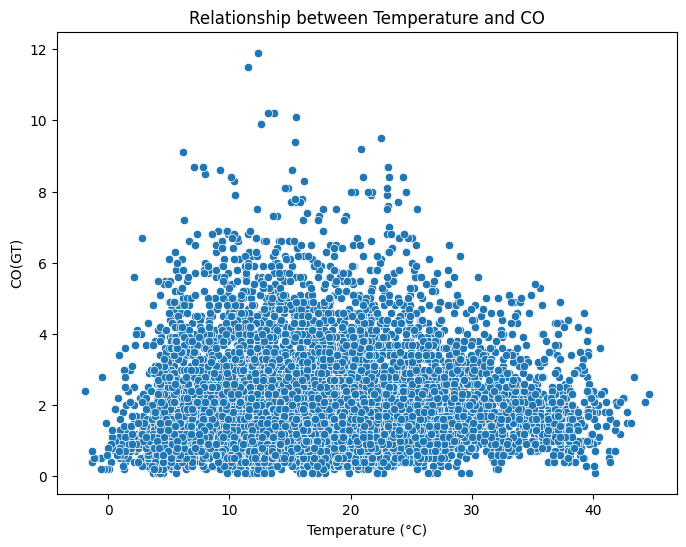

In [24]:
plt.figure(figsize=(8,6))
sns.scatterplot(x=df_filtered["T"], y=df_filtered["CO(GT)"])

plt.title("Relationship between Temperature and CO")
plt.xlabel("Temperature (°C)")
plt.ylabel("CO(GT)")

plt.show()


#VISUAL 4 – Boxplot (CO distribution)

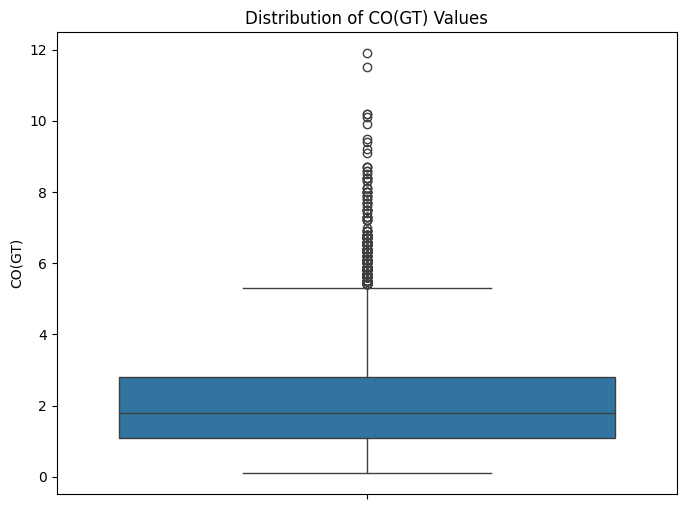

In [25]:
plt.figure(figsize=(8,6))
sns.boxplot(y=df_filtered["CO(GT)"])

plt.title("Distribution of CO(GT) Values")

plt.show()


### Reflection – Section 4

Different visualisation techniques were used to represent the dataset.
A line graph showed temperature variation across hours of the day.
A bar chart compared average CO levels by hour. A scatter plot
demonstrated the relationship between temperature and CO concentration.
A boxplot was used to identify outliers and understand data distribution.
These visualisations help in interpreting patterns and trends clearly.


# Section 5: GUI Development (16 marks)  

In this part, a graphical user interface (GUI) is developed using
Tkinter. The application allows users to engage with the dataset by
selecting different pollutants, viewing summary statistics, and
generating visualisations dynamically.


In [26]:
#import all required libraries

import tkinter as tk
from tkinter import ttk, messagebox
import matplotlib.pyplot as plt
import numpy as np


In [27]:
#Create Functions

def get_valid_data(column):
    return df[column][df[column] != -200]

def calculate_stats(column):
    values = get_valid_data(column)
    
    avg = round(values.mean(), 2)
    max_val = round(values.max(), 2)
    min_val = round(values.min(), 2)
    
    return avg, max_val, min_val

def show_statistics():
    col = dropdown.get()
    
    if col == "":
        messagebox.showerror("Error", "Please select a variable")
        return
    
    avg, max_val, min_val = calculate_stats(col)
    
    result_label.config(
        text=f"{col} Statistics\n"
             f"Average: {avg}\n"
             f"Maximum: {max_val}\n"
             f"Minimum: {min_val}"
    )

In [28]:
# Function for plot graph and clear output

def plot_graph():
    col = dropdown.get()
    
    if col == "":
        messagebox.showerror("Error", "Please select a variable")
        return
    
    values = get_valid_data(col)
    
    plt.figure(figsize=(8,5))
    plt.plot(values[:300])
    plt.title(f"{col} Trend (First 300 records)")
    plt.xlabel("Index")
    plt.ylabel(col)
    plt.grid(True)
    plt.show()



def clear_output():
    result_label.config(text="")



In [29]:
#Build main window

root = tk.Tk()
root.title("Air Quality Data Analysis System")
root.geometry("450x350")
root.resizable(False, False)



''

In [30]:
#Giving title and setting fonts

title_label = tk.Label(
    root, 
    text="Air Quality Analysis Dashboard", 
    font=("Arial", 14, "bold")
)
title_label.pack(pady=10)


In [31]:
#Create a dropdown menu 

columns = ["CO(GT)", "T", "NOx(GT)", "NO2(GT)", "C6H6(GT)"]

dropdown_label = tk.Label(root, text="Select Variable:")
dropdown_label.pack()

dropdown = ttk.Combobox(root, values=columns, state="readonly")
dropdown.pack(pady=5)


In [32]:
#Buttons frame
button_frame = tk.Frame(root)
button_frame.pack(pady=10)

stats_btn = tk.Button(
    button_frame, 
    text="Show Statistics", 
    command=show_statistics, 
    width=15
)
stats_btn.grid(row=0, column=0, padx=5)

plot_btn = tk.Button(
    button_frame, 
    text="Plot Graph", 
    command=plot_graph, 
    width=15
)
plot_btn.grid(row=0, column=1, padx=5)

clear_btn = tk.Button(
    button_frame, 
    text="Clear Output", 
    command=clear_output, 
    width=15
)
clear_btn.grid(row=1, column=0, columnspan=2, pady=5)




In [33]:
#output label

result_label = tk.Label(
    root, 
    text="", 
    font=("Arial", 10), 
    justify="left"
)
result_label.pack(pady=10)


In [ ]:
root.mainloop()


### Reflection – Section 5

A fully interactive GUI was developed using Tkinter.
Users can select different air quality variables from a dropdown menu
and view summary statistics including average, maximum, and minimum values.
Error handling ensures valid input selection.

The application also provides dynamic data visualisation by generating
line plots. Additional interface features such as clear output and
structured layout improve usability. This section demonstrates
event-driven programming, user interaction, and integration of data
analysis within a GUI environment.


# Section 6: Conclusion: Version Control, Critical Appraisal, Documentation (24 marks)  

In [ ]:
# Explanation and Documentation 

### Version Control (GitHub)

GitHub was used throughout the project to manage version control.
A dedicated repository was created to store the coursework files and
track incremental development.

After completing each section of the coursework, changes were committed
with clear commit messages describing the updates made. This demonstrates
a structured development process and allows previous versions of the
project to be reviewed if required.

Repository link:
https://olympus.ntu.ac.uk/n1420002/SOFT40161-Air-Quality-Analysis


### Code Documentation

All Python code is documented using:
- Clear comments explaining logic
- Function docstrings describing inputs and outputs
- Descriptive variable names

This improves readability, maintainability, and understanding of the
code for other users and future development.


### Critical Appraisal

This project successfully analysed a real-world air quality dataset.
Key programming concepts such as control structures, functions,
data handling, visualisation, and GUI development were applied.

Strengths of the project:
- Effective handling of missing values (-200 encoding)
- Modular function design for reusability
- Meaningful visualisations to identify patterns
- Interactive GUI for user engagement

Limitations:
- The dataset covers a single location only
- Advanced machine learning techniques were not applied

Future improvements:
- Use multiple datasets from different regions
- Apply predictive modelling techniques
- Enhance GUI with more interactive filters


### Conclusion

In conclusion, this coursework demonstrated practical Python
programming skills applied to real-world data analysis.

The project covered:
- Control structures for data processing
- Functions and modules for modular design
- Data cleaning and aggregation using Pandas
- Visualisation techniques using Matplotlib and Seaborn
- GUI development using Tkinter

All objectives of the coursework were successfully met.
This project enhanced my understanding of data analytics
and software development using Python.


# References:


Vito, S. (2016). UCI Machine Learning Repository. [online] archive.ics.uci.edu. 
Available at: https://archive.ics.uci.edu/dataset/360/air+quality.

Matplotlib (n.d.). Overview — Matplotlib 3.4.1 documentation. [online] matplotlib.org. Available at: https://matplotlib.org/stable/contents.html.

Pandas (2024). pandas documentation — pandas 1.0.1 documentation. [online] pandas.pydata.org. 
Available at: https://pandas.pydata.org/docs/.

Python Software Foundation (2019). tkinter — Python interface to Tcl/Tk — Python 3.7.2 documentation. [online] python.org. 
Available at: https://docs.python.org/3/library/tkinter.html.
‌

# Appendix:

### Appendix

Screenshots of the GUI application and generated plots
are included here to demonstrate functionality.
